In [1]:
# Google Colab Only
try:
    import google.colab  # noqa: F401

    # specify the version of DataEval (==X.XX.X) for versions other than the latest
    %pip install -q dataeval "maite-datasets[hf]>=0.0.25" "dataeval-plots>=0.0.19"
except Exception:
    pass

In [2]:
import difflib

import dataeval_plots as dep
import numpy as np
import polars as pl
from IPython.display import display
from maite_datasets.multiobject_tracking import VisDroneMOT

from dataeval import Metadata, Ontology
from dataeval.config import set_max_processes
from dataeval.core import label_alignment
from dataeval.data import DetectionCrops, EvenlySpaced, Indices, Relabel, SequenceFrames, View
from dataeval.quality import Outliers

set_max_processes(4)
_ = pl.Config.set_tbl_width_chars(160)
_ = pl.Config.set_tbl_rows(20)

In [3]:
dataset = VisDroneMOT(root="./data", image_set="val", download=True)
frames = SequenceFrames(dataset, EvenlySpaced(3))
CLASSES = [dataset.index2label[index] for index in sorted(dataset.index2label)]
print(f"{len(frames)} frames, classes: {CLASSES}")

21 frames, classes: ['pedestrian', 'people', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'awning-tricycle', 'bus', 'motor']


In [4]:
# TEST ASSERTION CELL ###
assert len(dataset) == 7
assert len(frames) == 21
assert len(CLASSES) == 10

In [5]:
TRUCK, BUS = CLASSES.index("truck"), CLASSES.index("bus")
# (frame, box) of the planted names, and the two frames replaced by images with no content.
TYPO, NAMELESS = (5, 12), (15, 11)
BLACK, EMPTY = 0, 6


class PlantedDefects:
    """Pass the frames through, with two boxes renamed and two images replaced."""

    def __init__(self, frames, *, typo, nameless, black, empty):
        self._frames, self._typo, self._nameless, self._black, self._empty = frames, typo, nameless, black, empty
        names = frames.metadata["index2label"]
        self.metadata = {"id": "visdrone-planted", "index2label": {**names, 10: "truvk", 11: "*"}}

    def __len__(self):
        return len(self._frames)

    def __getitem__(self, index):
        image, target, datum = self._frames[index]
        labels = np.array(target.labels, copy=True)
        for (frame, box), label in ((self._typo, 10), (self._nameless, 11)):
            if index == frame:
                labels[box] = label
        if index == self._black:
            image = np.zeros_like(np.asarray(image))
        if index == self._empty:
            image = np.zeros((3, 0, 0), dtype=np.uint8)
        return image, target._replace(labels=labels), datum


planted = PlantedDefects(frames, typo=TYPO, nameless=NAMELESS, black=BLACK, empty=EMPTY)

In [6]:
# TEST ASSERTION CELL ###
assert np.asarray(frames[TYPO[0]][1].labels)[TYPO[1]] == TRUCK
assert np.asarray(frames[NAMELESS[0]][1].labels)[NAMELESS[1]] == BUS
assert {BLACK, EMPTY}.isdisjoint({TYPO[0], NAMELESS[0]})

In [7]:
def box_counts(data, column="boxes"):
    """Count the boxes of each class name in a detection dataset."""
    names = data.metadata["index2label"]
    rows = Metadata(data).rows_at("instance")
    counts = rows.group_by("class_label").len(name=column).sort("class_label")
    return counts.select(pl.col("class_label").replace_strict(names, return_dtype=pl.String).alias("class"), column)


counts = box_counts(planted)
display(counts)

class,boxes
str,u32
"""pedestrian""",230
"""people""",153
"""bicycle""",71
"""car""",283
"""van""",57
"""truck""",8
"""tricycle""",31
"""awning-tricycle""",16
"""bus""",4


In [8]:
VISDRONE = Ontology.from_hierarchy(CLASSES)
alignment = label_alignment(counts["class"].to_list(), VISDRONE)
print("Names not on the class list:", list(alignment["unaligned_source"]))

Names not on the class list: ['truvk', '*']


In [9]:
# TEST ASSERTION CELL ###
assert sorted(alignment["unaligned_source"]) == ["*", "truvk"]
assert counts.filter(pl.col("class").is_in(["*", "truvk"]))["boxes"].to_list() == [1, 1]

In [10]:
print({name: difflib.get_close_matches(name, CLASSES, n=3, cutoff=0) for name in alignment["unaligned_source"]})

{'truvk': ['truck', 'motor', 'tricycle'], '*': ['van', 'truck', 'tricycle']}


In [11]:
# TEST ASSERTION CELL ###
assert difflib.get_close_matches("truvk", CLASSES, n=1, cutoff=0) == ["truck"]
assert all(difflib.SequenceMatcher(None, "*", name).ratio() == 0 for name in CLASSES)

In [12]:
outliers = Outliers().evaluate(planted)
flagged = outliers.data().select("item_index", "metric_name", "metric_value", "bound").sort("item_index", "metric_name")
display(flagged)

item_index,metric_name,metric_value,bound
i64,cat,f64,f64
0,"""contrast""",0.0,0.337467
0,"""depth""",1.0,6.18384
0,"""entropy""",0.0,2.289908
0,"""zeros""",1.0,0.119621
6,"""missing""",1.0,0.247097
12,"""saturated_fraction""",0.2966,0.012548
13,"""saturated_fraction""",0.299187,0.012548
14,"""saturated_fraction""",0.297595,0.012548


In [13]:
# TEST ASSERTION CELL ###
flagged_items = sorted(set(flagged["item_index"].to_list()))
ordinary = [item for item in flagged_items if item not in (BLACK, EMPTY)]
assert {BLACK, EMPTY} <= set(flagged_items)
assert len(flagged_items) == 5
assert set(flagged.filter(pl.col("item_index") == BLACK)["metric_name"].to_list()) == {
    "contrast",
    "depth",
    "entropy",
    "zeros",
}
assert flagged.filter(pl.col("item_index") == EMPTY)["metric_name"].to_list() == ["missing"]
black_values = dict(zip(*flagged.filter(pl.col("item_index") == BLACK)[["metric_name", "metric_value"]], strict=True))
assert black_values["zeros"] == 1
assert black_values["depth"] == 1
assert black_values["contrast"] == 0
assert black_values["entropy"] == 0
assert flagged.filter(pl.col("item_index") == EMPTY)["metric_value"].to_list() == [1]
assert set(flagged.filter(pl.col("item_index").is_in(ordinary))["metric_name"].to_list()) == {"saturated_fraction"}
assert all(0.25 <= value <= 0.40 for value in flagged.filter(pl.col("item_index").is_in(ordinary))["metric_value"])

In [14]:
print("Shape of frame 6:", planted[6][0].shape)
print("Videos of frames 12, 13 and 14:", {planted[frame][2]["source_id"] for frame in (12, 13, 14)})

Shape of frame 6: (3, 0, 0)


Videos of frames 12, 13 and 14: {'uav0000268_05773_v'}


In [15]:
# TEST ASSERTION CELL ###
assert planted[EMPTY][0].shape == (3, 0, 0)
assert EMPTY == 6
assert BLACK == 0
assert ordinary == [12, 13, 14]
assert len({planted[item][2]["source_id"] for item in ordinary}) == 1

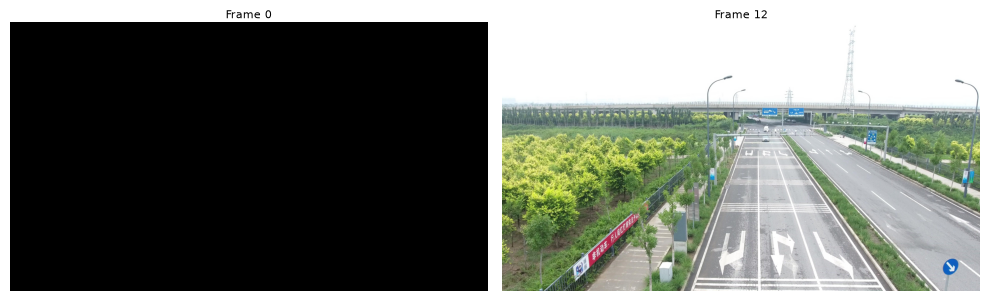

In [16]:
dep.plot([planted[0][0], planted[12][0]], figsize=(10, 3), images_per_row=2, titles=["Frame 0", "Frame 12"])

In [17]:
empty_frames = [0, 6]

In [18]:
# TEST ASSERTION CELL ###
assert empty_frames == sorted([BLACK, EMPTY])

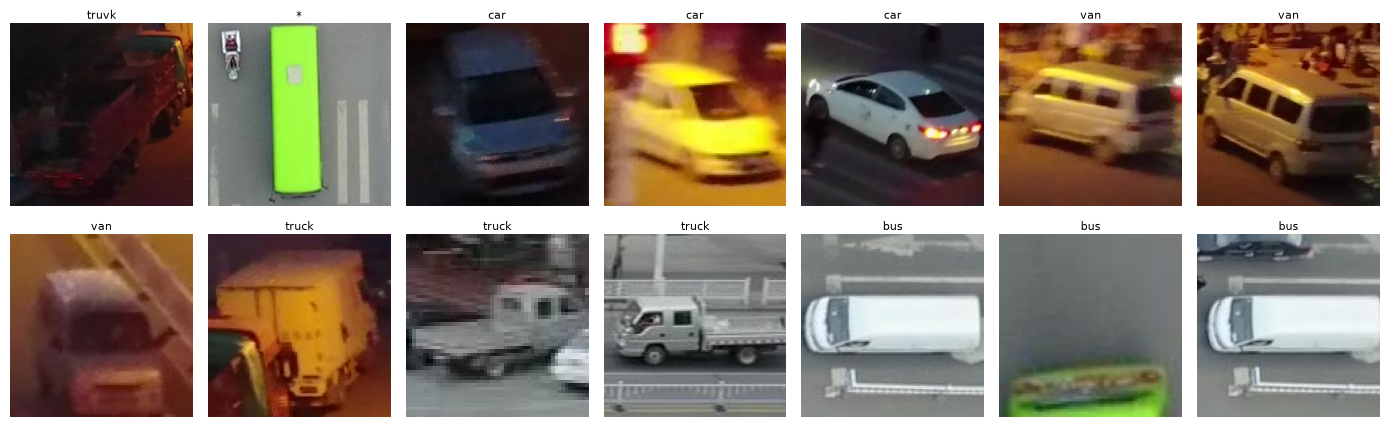

In [19]:
clean = View(planted, Indices(empty_frames, exclude=True))
crops = DetectionCrops(clean)
labels = np.asarray(crops.labels)
names = planted.metadata["index2label"]
label_of = {name: index for index, name in names.items()}
shown = [int(np.flatnonzero(labels == label_of[name])[0]) for name in ("truvk", "*")]
for name in ("car", "van", "truck", "bus"):
    shown += [int(index) for index in np.flatnonzero(labels == label_of[name])[:3]]
dep.plot(
    [crops[index][0] for index in shown],
    figsize=(14, 4.5),
    images_per_row=7,
    titles=[names[int(labels[index])] for index in shown],
)

In [20]:
# TEST ASSERTION CELL ###
assert len(shown) == 14
# The `*` box and the middle bus example are one tracked vehicle, in two frames of one video.
assert crops.track_ids[shown[1]] == crops.track_ids[shown[-2]]
assert crops.item_indices[shown[-2]] > crops.item_indices[shown[1]]
assert (
    clean[int(crops.item_indices[shown[1]])][2]["source_id"]
    == clean[int(crops.item_indices[shown[-2]])][2]["source_id"]
)

In [21]:
reviewed = {"truvk": "truck", "*": "bus"}

In [22]:
fixed = View(
    planted,
    [
        Indices(empty_frames, exclude=True),
        Relabel({**alignment["class_remap"], **reviewed}, target=VISDRONE, on_unmatched="raise", drop_empty=False),
    ],
)
left_out = View(planted, Indices(empty_frames))
table = (
    box_counts(planted, "planted")
    .join(box_counts(left_out, "on the left-out frames"), on="class", how="left")
    .join(box_counts(fixed, "fixed"), on="class", how="left")
    .fill_null(0)
)
display(table)
print(f"Frames: {len(planted)} planted, {len(fixed)} fixed")

class,planted,on the left-out frames,fixed
str,u32,u32,u32
"""pedestrian""",230,42,188
"""people""",153,36,117
"""bicycle""",71,18,53
"""car""",283,30,253
"""van""",57,2,55
"""truck""",8,0,9
"""tricycle""",31,0,31
"""awning-tricycle""",16,0,16
"""bus""",4,0,5


Frames: 21 planted, 19 fixed


In [23]:
# TEST ASSERTION CELL ###
before = dict(zip(table["class"], table["planted"], strict=True))
out = dict(zip(table["class"], table["on the left-out frames"], strict=True))
after = box_counts(fixed)
after = dict(zip(after["class"], after["boxes"], strict=True))
assert set(after) <= set(CLASSES)
assert after["truck"] == before["truck"] - out["truck"] + 1
assert after["bus"] == before["bus"] - out["bus"] + 1
assert sum(after.values()) == sum(before.values()) - sum(out.values())
assert sum(out.values()) == 144
assert len(fixed) == len(planted) - 2